# 05_model_xgboost.ipynb

## 목차

### 1. 환경 세팅 및 데이터 로드
### 2. 데이터셋 분할
### 3. 베이스라인 모델 학습
### 4. 하이퍼파라미터 튜닝
### 5. 최종 모델 학습 및 평가
### 6. 피처 중요도 분석
### 7. 결과 저장

## 1. 환경 세팅 및 데이터 로드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import time, os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix, roc_curve, classification_report

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format
print('라이브러리 임포트 완료')

라이브러리 임포트 완료


In [2]:
df = pd.read_csv('./data/hnm_churn_processed.csv')
print(f'데이터 shape: {df.shape}')
print(f'결측치 합계: {df.isnull().sum().sum()}')

데이터 shape: (1143652, 45)
결측치 합계: 330842


## 2. 데이터셋 분할

In [3]:
# 2. 분할 데이터 로드
# 03_preprocessing에서 저장한 분할 데이터를 불러옵니다.
# random_state=42 Stratified Split 결과와 동일합니다.
X_train = pd.read_csv('./data/X_train.csv')
X_val   = pd.read_csv('./data/X_val.csv')
y_train = pd.read_csv('./data/y_train.csv').squeeze()
y_val   = pd.read_csv('./data/y_val.csv').squeeze()

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')
print(f'y_train 이탈률: {y_train.mean():.4f}')
print(f'y_val   이탈률: {y_val.mean():.4f}')

X_train: (914921, 44), X_val: (228731, 44)
y_train 이탈률: 0.5002
y_val   이탈률: 0.5002


## 3. 베이스라인 모델 학습

In [4]:
baseline_model = xgb.XGBClassifier(
    random_state=42, n_jobs=-1, verbosity=0,
    eval_metric='auc', use_label_encoder=False
)

start = time.time()
baseline_model.fit(X_train, y_train)
baseline_time = time.time() - start

baseline_pred  = baseline_model.predict(X_val)
baseline_proba = baseline_model.predict_proba(X_val)[:, 1]

print('--- XGBoost 베이스라인 성능 ---')
print(f'Accuracy : {accuracy_score(y_val, baseline_pred):.4f}')
print(f'AUC-ROC  : {roc_auc_score(y_val, baseline_proba):.4f}')
print(f'F1-Score : {f1_score(y_val, baseline_pred):.4f}')
print(f'학습 시간 : {baseline_time:.1f}초')

--- XGBoost 베이스라인 성능 ---
Accuracy : 0.7684
AUC-ROC  : 0.8481
F1-Score : 0.7717
학습 시간 : 7.9초


## 4. 하이퍼파라미터 튜닝

In [5]:
param_grid = {
    'max_depth'       : [4, 6, 8],
    'learning_rate'   : [0.05, 0.1],
    'n_estimators'    : [200, 300],
    'subsample'       : [0.7, 0.9],
    'colsample_bytree': [0.7, 0.9]
}

xgb_base = xgb.XGBClassifier(
    random_state=42, n_jobs=-1, verbosity=0,
    eval_metric='auc', use_label_encoder=False
)

grid_search = GridSearchCV(
    estimator=xgb_base, param_grid=param_grid,
    scoring='roc_auc', cv=3, n_jobs=-1, verbose=1
)
grid_search.fit(X_train, y_train)

print('--- 최적 파라미터 ---')
print(grid_search.best_params_)
print(f'CV 최고 AUC: {grid_search.best_score_:.4f}')

Fitting 3 folds for each of 48 candidates, totalling 144 fits
--- 최적 파라미터 ---
{'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 8, 'n_estimators': 300, 'subsample': 0.9}
CV 최고 AUC: 0.8480


## 5. 최종 모델 학습 및 평가

In [6]:
best_params = grid_search.best_params_

final_model = xgb.XGBClassifier(
    **best_params,
    random_state=42, n_jobs=-1, verbosity=0,
    eval_metric='auc', use_label_encoder=False,
    early_stopping_rounds=50
)

start = time.time()
final_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)
train_time = time.time() - start
print(f'최종 학습 완료 ({train_time:.1f}초)')

최종 학습 완료 (57.1초)


In [7]:
y_pred  = final_model.predict(X_val)
y_proba = final_model.predict_proba(X_val)[:, 1]

final_acc = accuracy_score(y_val, y_pred)
final_auc = roc_auc_score(y_val, y_proba)
final_f1  = f1_score(y_val, y_pred)

print('--- XGBoost 최종 성능 ---')
print(f'Accuracy : {final_acc:.4f}')
print(f'AUC-ROC  : {final_auc:.4f}')
print(f'F1-Score : {final_f1:.4f}')
print(f'학습 시간 : {train_time:.1f}초')
print()
print(classification_report(y_val, y_pred, target_names=['유지(0)', '이탈(1)']))

--- XGBoost 최종 성능 ---
Accuracy : 0.7690
AUC-ROC  : 0.8487
F1-Score : 0.7721
학습 시간 : 57.1초

              precision    recall  f1-score   support

       유지(0)       0.78      0.76      0.77    114320
       이탈(1)       0.76      0.78      0.77    114411

    accuracy                           0.77    228731
   macro avg       0.77      0.77      0.77    228731
weighted avg       0.77      0.77      0.77    228731



c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\09048\AppData\Local\Temp\ipykernel_27676\2117146928.py:9: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_27676\2117146928.py:9: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG})

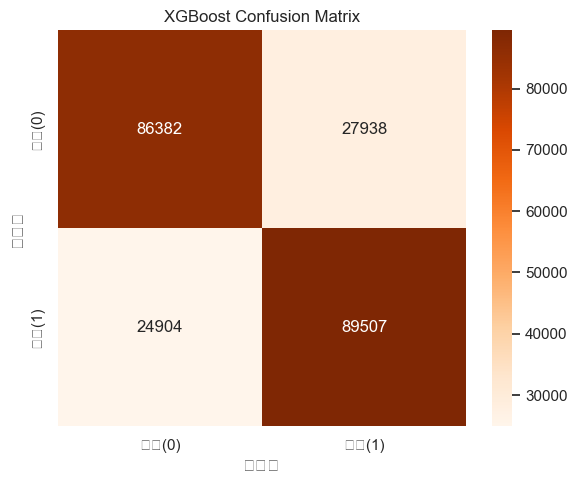

In [8]:
# Confusion Matrix
cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['유지(0)', '이탈(1)'], yticklabels=['유지(0)', '이탈(1)'])
plt.title('XGBoost Confusion Matrix')
plt.ylabel('실제값')
plt.xlabel('예측값')
plt.tight_layout()
plt.show()

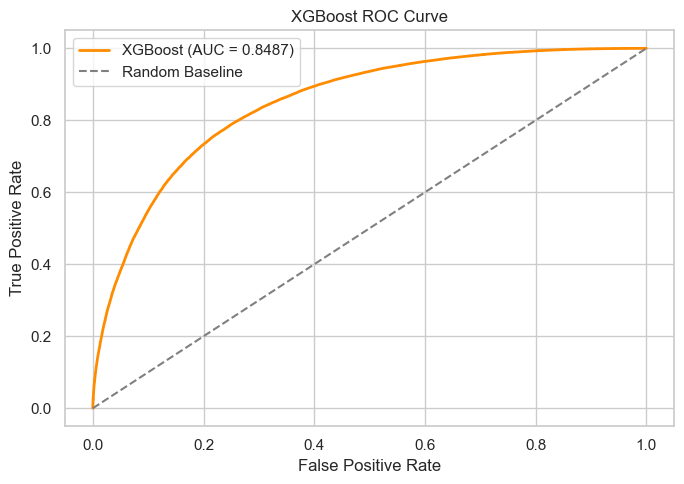

In [9]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_val, y_proba)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'XGBoost (AUC = {final_auc:.4f})', color='darkorange', lw=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('XGBoost ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

## 6. 피처 중요도 분석

C:\Users\09048\AppData\Local\Temp\ipykernel_27676\102668838.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=importance_df, palette='Oranges_r')


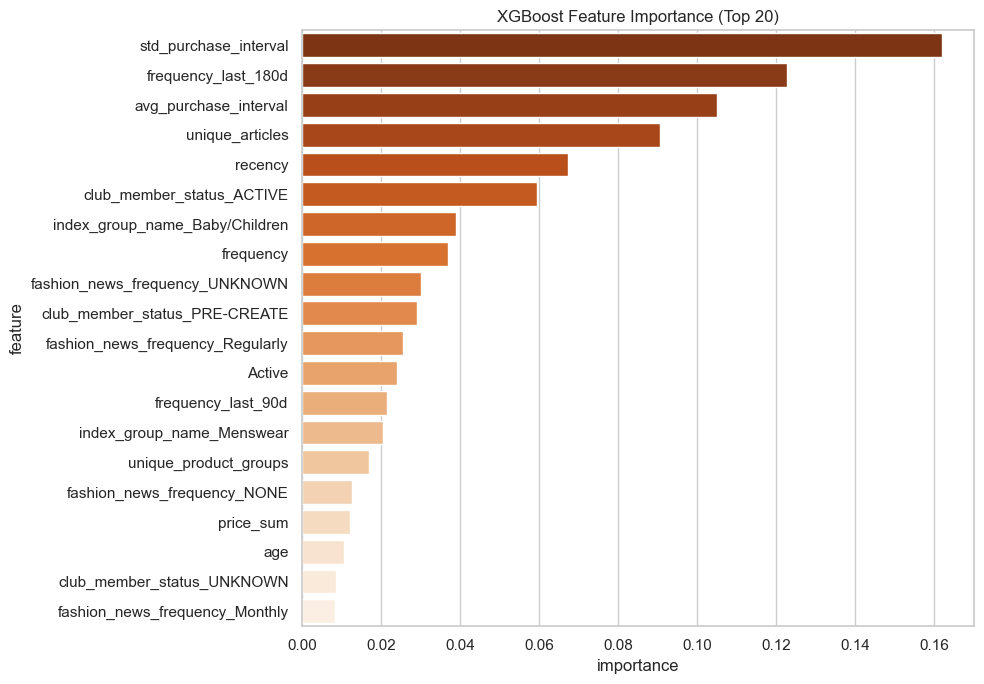

--- 피처 중요도 Top 10 ---
                       feature  importance
         std_purchase_interval      0.1620
           frequency_last_180d      0.1227
         avg_purchase_interval      0.1050
               unique_articles      0.0907
                       recency      0.0673
     club_member_status_ACTIVE      0.0596
index_group_name_Baby/Children      0.0391
                     frequency      0.0369
fashion_news_frequency_UNKNOWN      0.0302
 club_member_status_PRE-CREATE      0.0290


In [10]:
importance_df = pd.DataFrame({
    'feature'   : X_train.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

plt.figure(figsize=(10, 7))
sns.barplot(x='importance', y='feature', data=importance_df, palette='Oranges_r')
plt.title('XGBoost Feature Importance (Top 20)')
plt.tight_layout()
plt.show()

print('--- 피처 중요도 Top 10 ---')
print(importance_df[['feature', 'importance']].head(10).to_string(index=False))

## 7. 결과 저장

In [11]:
os.makedirs('./results', exist_ok=True)

result = pd.DataFrame([{
    'model'     : 'XGBoost',
    'accuracy'  : round(final_acc, 4),
    'auc_roc'   : round(final_auc, 4),
    'f1_score'  : round(final_f1, 4),
    'train_time': round(train_time, 1)
}])

result.to_csv('./results/xgboost_result.csv', index=False)
print('결과 저장 완료')
print(result.to_string(index=False))

결과 저장 완료
  model  accuracy  auc_roc  f1_score  train_time
XGBoost    0.7690   0.8487    0.7721     57.1000
